In [ ]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt

# Start scope for Brian2 simulation
start_scope()

# Simulation time
time_simu = 150 * second
#save_interval = 0.1 * second
#change_interval = 10 * second
#n_steps = int(time_simu / change_interval)

# Homeostatic plasticity parameters
alpha = 0.0005
tau_homeo = 20 * second
target_firing_rate = 5
w_max = 2

# Neuron model parameters
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons

V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF
g_m_E = 25. * nS
g_m_I = 20. * nS
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# Synaptic parameters
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 800. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 800. / N_E
tau_AMPA = 2. * ms

g_NMDA_E = 0.327 * nS * 800. / N_E
g_NMDA_I = 0.258 * nS * 800. / N_E
tau_NMDA_rise = 2. * ms
tau_NMDA_decay = 100. * ms
alpha_nmda = 0.5 / ms
Mg2 = 1.

g_GABA_E = 1.25 * nS * 200. / N_I
g_GABA_I = 0.973 * nS * 200. / N_I
tau_GABA = 10. * ms

# Neuron model equations (biologically detailed)
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_NMDA_rec = g_NMDA_E * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_NMDA_rec = g_NMDA_I * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

# Define populations
P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

eqs_glut = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
s_NMDA_tot_post = w * s_NMDA : 1 (summed)
ds_NMDA / dt = - s_NMDA / tau_NMDA_decay + alpha * x * (1 - s_NMDA) : 1 (clock-driven)
dx / dt = - x / tau_NMDA_rise : 1 (clock-driven)
w : 1
'''

eqs_pre_glut = '''
s_AMPA += w
x += 1
'''

eqs_pre_gaba = '''
s_GABA += 1
'''

# E to E
C_E_E = Synapses(P_E, P_E, model=eqs_glut, on_pre=eqs_pre_glut, on_post='''synaptic_activity += 1''', method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
# I to I
C_I_I = Synapses(P_I, P_I, on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')

# I to E
C_I_E = Synapses(P_I, P_E, on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()


# Synaptic weight dynamics (homeostatic plasticity)
C_E_E.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0, w_max)
''', dt=100 * ms)

# External Poisson input (replacing the PoissonGroup stimulation)
C_P_E = PoissonInput(P_E, 's_AMPA_ext', 80, rate=3 * Hz, value='1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', 80, rate=3 * Hz, value='1')

# Monitors
spikemon = SpikeMonitor(P_E)
rate_mon = PopulationRateMonitor(P_E)

# Run the simulation
run(time_simu, report="text")

# Plotting results
plt.figure()
plt.plot(spikemon.t / ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(rate_mon.t / ms, rate_mon.smooth_rate(window='flat', width=100 * ms) / Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()


In [ ]:
from brian2 import *

# populations
N = 100
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA (excitatory)
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 800. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 800. / N_E
tau_AMPA = 2. * ms

# NMDA (excitatory)
g_NMDA_E = 0.327 * nS * 800. / N_E
g_NMDA_I = 0.258 * nS * 800. / N_E
tau_NMDA_rise = 2. * ms
tau_NMDA_decay = 100. * ms
alpha = 0.5 / ms
Mg2 = 1.

# GABAergic (inhibitory)
g_GABA_E = 1.25 * nS * 200. / N_I
g_GABA_I = 0.973 * nS * 200. / N_I
tau_GABA = 10. * ms

# subpopulations
f = 0.1
p = 5
N_sub = int(N_E * f)
N_non = int(N_E * (1. - f * p))
w_plus = 2.1
w_minus = 1. - f * (w_plus - 1.) / (1. - f)

# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)

I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp

I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

I_NMDA_rec = g_NMDA_E * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1

I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)

I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp

I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

I_NMDA_rec = g_NMDA_I * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1

I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

eqs_glut = '''
s_NMDA_tot_post = w * s_NMDA : 1 (summed)
ds_NMDA / dt = - s_NMDA / tau_NMDA_decay + alpha * x * (1 - s_NMDA) : 1 (clock-driven)
dx / dt = - x / tau_NMDA_rise : 1 (clock-driven)
w : 1
'''

eqs_pre_glut = '''
s_AMPA += w
x += 1
'''

eqs_pre_gaba = '''
s_GABA += 1
'''

# E to E
C_E_E = Synapses(P_E, P_E, model=eqs_glut, on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1

for pi in range(N_non, N_non + p * N_sub, N_sub):

    # internal other subpopulation to current nonselective
    C_E_E.w[C_E_E.indices[:, pi:pi + N_sub]] = w_minus

    # internal current subpopulation to current subpopulation
    C_E_E.w[C_E_E.indices[pi:pi + N_sub, pi:pi + N_sub]] = w_plus

# E to I
C_E_I = Synapses(P_E, P_I, model=eqs_glut, on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')

# I to E
C_I_E = Synapses(P_I, P_E, on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')

# at 1s, select population 1
C_selection = int(f * C_ext)
rate_selection = 25 * Hz
stimuli1 = TimedArray(np.r_[np.zeros(40), np.ones(2), np.zeros(100)], dt=25 * ms)
input1 = PoissonInput(P_E[N_non:N_non + N_sub], 's_AMPA_ext', C_selection, rate_selection, 'stimuli1(t)')

# at 2s, select population 2
stimuli2 = TimedArray(np.r_[np.zeros(80), np.ones(2), np.zeros(100)], dt=25 * ms)
input2 = PoissonInput(P_E[N_non + N_sub:N_non + 2 * N_sub], 's_AMPA_ext', C_selection, rate_selection, 'stimuli2(t)')

# at 4s, reset selection
stimuli_reset = TimedArray(np.r_[np.zeros(120), np.ones(2), np.zeros(100)], dt=25 * ms)
input_reset_I = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate_selection, 'stimuli_reset(t)')
input_reset_E = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate_selection, 'stimuli_reset(t)')

# monitors
N_activity_plot = 15
sp_E_sels = [SpikeMonitor(P_E[pi:pi + N_activity_plot]) for pi in range(N_non, N_non + p * N_sub, N_sub)]
sp_E = SpikeMonitor(P_E[:N_activity_plot])
sp_I = SpikeMonitor(P_I[:N_activity_plot])

r_E_sels = [PopulationRateMonitor(P_E[pi:pi + N_sub]) for pi in range(N_non, N_non + p * N_sub, N_sub)]
r_E = PopulationRateMonitor(P_E[:N_non])
r_I = PopulationRateMonitor(P_I)

# simulate, can be long >120s
net = Network(collect())
net.add(sp_E_sels)
net.add(r_E_sels)
net.run(4 * second, report='stdout')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')

plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='nonselective')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='inhibitory')

for i, r_E_sel in enumerate(r_E_sels[::-1]):
    plot(r_E_sel.t / ms, r_E_sel.smooth_rate(width=25 * ms) / Hz,
         label=f"selective {p - i}")

legend()
figure()

title(f"Population activities ({N_activity_plot} neurons/pop)")
xlabel('ms')
yticks([])

plot(sp_E.t / ms, sp_E.i + (p + 1) * N_activity_plot, '.', markersize=2,
     label="nonselective")
plot(sp_I.t / ms, sp_I.i + p * N_activity_plot, '.', markersize=2, label="inhibitory")

for i, sp_E_sel in enumerate(sp_E_sels[::-1]):
    plot(sp_E_sel.t / ms, sp_E_sel.i + (p - i - 1) * N_activity_plot, '.', markersize=2,
         label=f"selective {p - i}")

legend()
show()

In [ ]:
from brian2 import *
start_scope()

# populations
N = 1000
N_E = int(N * 0.8)  # pyramidal neurons
N_I = int(N * 0.2)  # interneurons

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA (excitatory)
g_AMPA_ext_E = 2.08 * nS
g_AMPA_rec_E = 0.104 * nS * 800. / N_E
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS * 800. / N_E
tau_AMPA = 2. * ms

# NMDA (excitatory)
g_NMDA_E = 0.327 * nS * 800. / N_E
g_NMDA_I = 0.258 * nS * 800. / N_E
tau_NMDA_rise = 2. * ms
tau_NMDA_decay = 100. * ms
alpha = 0.5 / ms
Mg2 = 1.

# GABAergic (inhibitory)
g_GABA_E = 1.25 * nS * 200. / N_I
g_GABA_I = 0.973 * nS * 200. / N_I
tau_GABA = 10. * ms

# subpopulations
f = 0.1
p = 5
N_sub = int(N_E * f)
N_non = int(N_E * (1. - f * p))
w_plus = 2.1
w_minus = 1. - f * (w_plus - 1.) / (1. - f)

# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)

I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp

I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

I_NMDA_rec = g_NMDA_E * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1

I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)

I_syn = I_AMPA_ext + I_AMPA_rec + I_NMDA_rec + I_GABA_rec : amp

I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1

I_NMDA_rec = g_NMDA_I * (v - V_E) / (1 + Mg2 * exp(-0.062 * v / mV) / 3.57) * s_NMDA_tot : amp
s_NMDA_tot : 1

I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

eqs_glut = '''
s_NMDA_tot_post = w * s_NMDA : 1 (summed)
ds_NMDA / dt = - s_NMDA / tau_NMDA_decay + alpha * x * (1 - s_NMDA) : 1 (clock-driven)
dx / dt = - x / tau_NMDA_rise : 1 (clock-driven)
w : 1
'''

eqs_pre_glut = '''
s_AMPA += w
x += 1
'''

eqs_pre_gaba = '''
s_GABA += 1
'''

# E to E
C_E_E = Synapses(P_E, P_E, model=eqs_glut, on_pre=eqs_pre_glut, method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1

for pi in range(N_non, N_non + p * N_sub, N_sub):

    # internal other subpopulation to current nonselective
    C_E_E.w[C_E_E.indices[:, pi:pi + N_sub]] = w_minus

    # internal current subpopulation to current subpopulation
    C_E_E.w[C_E_E.indices[pi:pi + N_sub, pi:pi + N_sub]] = w_plus

# E to I
C_E_I = Synapses(P_E, P_I, model=eqs_glut, on_pre=eqs_pre_glut, method='euler')
C_E_I.connect()
C_E_I.w[:] = 1

# I to I
C_I_I = Synapses(P_I, P_I, on_pre=eqs_pre_gaba, method='euler')
C_I_I.connect('i != j')

# I to E
C_I_E = Synapses(P_I, P_E, on_pre=eqs_pre_gaba, method='euler')
C_I_E.connect()

# external noise
C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')

# at 1s, select population 1
C_selection = int(f * C_ext)
rate_selection = 25 * Hz
stimuli1 = TimedArray(np.r_[np.zeros(40), np.ones(2), np.zeros(100)], dt=25 * ms)
input1 = PoissonInput(P_E[N_non:N_non + N_sub], 's_AMPA_ext', C_selection, rate_selection, 'stimuli1(t)')

# at 2s, select population 2
stimuli2 = TimedArray(np.r_[np.zeros(80), np.ones(2), np.zeros(100)], dt=25 * ms)
input2 = PoissonInput(P_E[N_non + N_sub:N_non + 2 * N_sub], 's_AMPA_ext', C_selection, rate_selection, 'stimuli2(t)')

# at 4s, reset selection
stimuli_reset = TimedArray(np.r_[np.zeros(120), np.ones(2), np.zeros(100)], dt=25 * ms)
input_reset_I = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate_selection, 'stimuli_reset(t)')
input_reset_E = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate_selection, 'stimuli_reset(t)')

# monitors
N_activity_plot = 15
sp_E_sels = [SpikeMonitor(P_E[pi:pi + N_activity_plot]) for pi in range(N_non, N_non + p * N_sub, N_sub)]
sp_E = SpikeMonitor(P_E[:N_activity_plot])
sp_I = SpikeMonitor(P_I[:N_activity_plot])

r_E_sels = [PopulationRateMonitor(P_E[pi:pi + N_sub]) for pi in range(N_non, N_non + p * N_sub, N_sub)]
r_E = PopulationRateMonitor(P_E[:N_non])
r_I = PopulationRateMonitor(P_I)

# simulate, can be long >120s
net = Network(collect())
net.add(sp_E_sels)
net.add(r_E_sels)
net.run(4 * second, report='text')

# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')

plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='nonselective')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='inhibitory')

for i, r_E_sel in enumerate(r_E_sels[::-1]):
    plot(r_E_sel.t / ms, r_E_sel.smooth_rate(width=25 * ms) / Hz,
         label=f"selective {p - i}")

legend()
figure()

title(f"Population activities ({N_activity_plot} neurons/pop)")
xlabel('ms')
yticks([])

plot(sp_E.t / ms, sp_E.i + (p + 1) * N_activity_plot, '.', markersize=2,
     label="nonselective")
plot(sp_I.t / ms, sp_I.i + p * N_activity_plot, '.', markersize=2, label="inhibitory")

for i, sp_E_sel in enumerate(sp_E_sels[::-1]):
    plot(sp_E_sel.t / ms, sp_E_sel.i + (p - i - 1) * N_activity_plot, '.', markersize=2,
         label=f"selective {p - i}")

legend()
show()

WARNING    'j' is an internal variable of group 'synapses_12', but also exists in the run namespace with the value 78. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


WARNING    'i' is an internal variable of group 'synapses_12', but also exists in the run namespace with the value 79. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


RuntimeError: poissongroup has already been simulated, cannot add it to the network. If you were trying to remove and add an object to temporarily stop it from being run, set its active flag to False instead.

WARNING    'i' is an internal variable of group 'synapses_5', but also exists in the run namespace with the value 79. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_10', but also exists in the run namespace with the value 112.36833565 * psiemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_10', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 150. s
12.3304 s (8%) simulated in 10s, estimated 1m 52s remaining.
25.2426 s (16%) simulated in 20s, estimated 1m 39s remaining.
34.204 s (22%) simulated in 30s, estimated 1m 42s remaining.
42.4709 s (28%) simulated in 40s, estimated 1m 41s remaining.
48.8201 s (32%) simulated in 50s, estimated 1m 44s remaining.
56.2429 s (37%) simulated in 1m 0s, estimated 1m 40s remaining.
62.529 s (41%) simulated in 1m 10s, estimated 1m 38s remaining.
68.7229 s (45%) simulated in 1m 20s, estimated 1m 35s remaining.
74.8065 s (49%) simulated in 1m 30s, estimated 1m 30s remaining.
79.7945 s (53%) simulated in 1m 40s, estimated 1m 28s remaining.
84.9609 s (56%) simulated in 1m 50s, estimated 1m 24s remaining.
89.7953 s (59%) simulated in 2m 0s, estimated 1m 20s remaining.
94.8004 s (63%) simulated in 2m 10s, estimated 1m 16s remaining.
99.5374 s (66%) simulated in 2m 20s, estimated 1m 11s remaining.
109.6646 s (73%) simulated in 2m 30s, estimated 55s rem

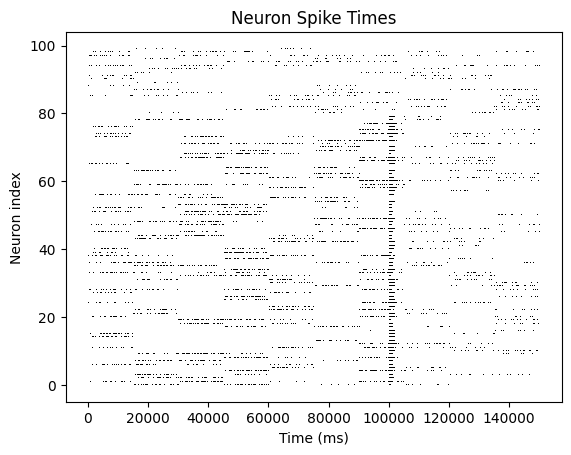

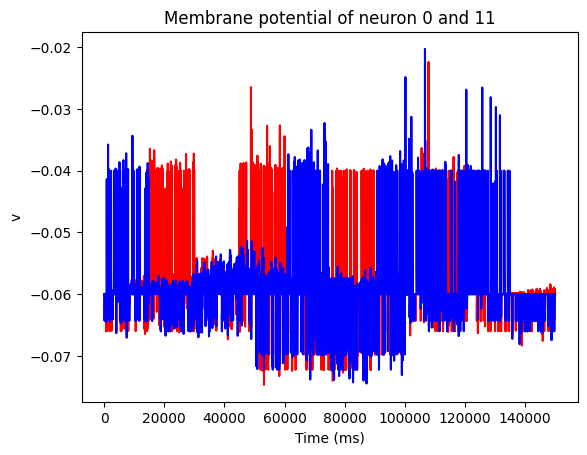

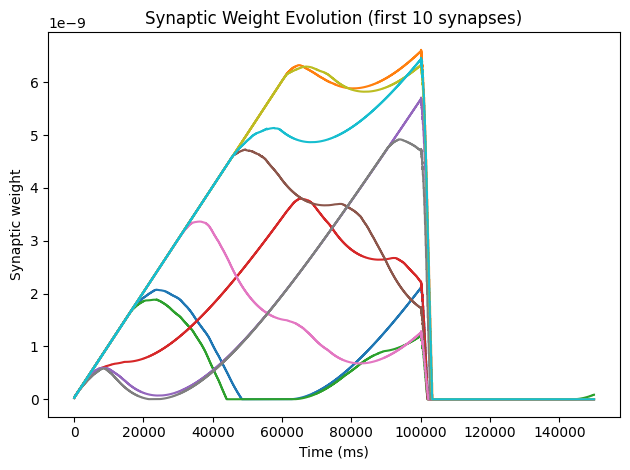

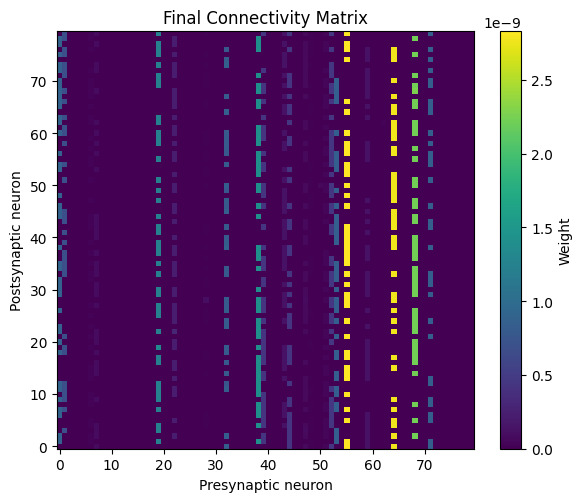

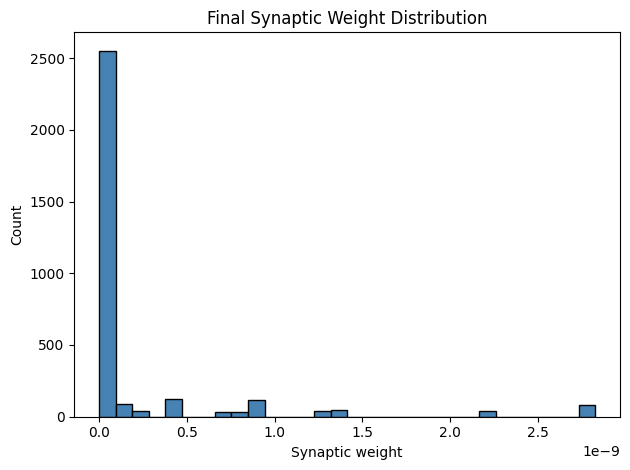

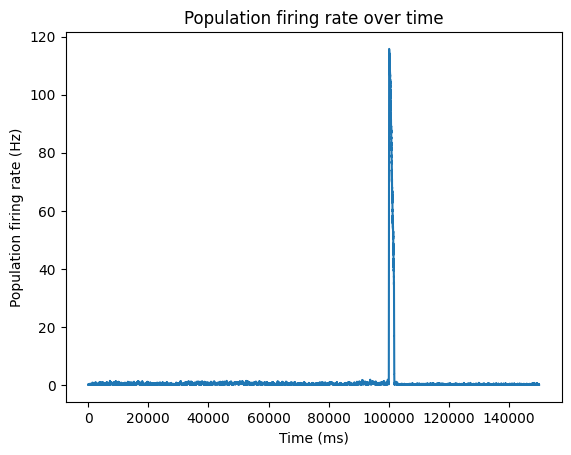

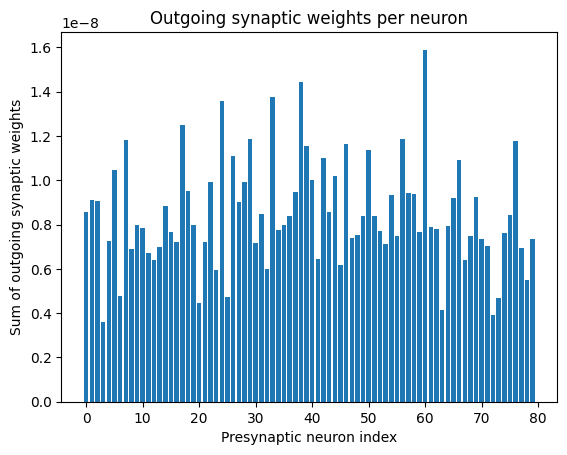

<Figure size 640x480 with 0 Axes>

In [29]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

N_e = 80 
N_i = 20  
N = N_e + N_i
time_simu = 150*second
refractory_period = 5*ms

tau_homeo = 20*second
target_firing_rate = 10 
alpha = 0.001*nS
w_max = 100*nS

stim_N = 30
stim_rate = 3*Hz
change_interval = 15*second
n_steps = int(time_simu/change_interval)


# alcohol‐withdrawal current window
t_on       = 50*second
t_off      = 100*second

#Neuron cst
E_l    = -60.0*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
V_th   = -40*mV
V_r    = E_l

alco_e= 0.5
alco_i= 2
eqs_neurons = '''
dv/dt = (g_l*(E_l-v) + g_e*(1-alco_e*aa)*(E_e-v) + g_i*(1+alco_i*aa)*(E_i-v) + I)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens  
dg_i/dt = -g_i/tau_i : siemens
aa = int(t >= t_on and t < t_off) : 1
I : ampere
'''


neurons = NeuronGroup(
    N, model=eqs_neurons,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l' #+ rand()*(V_th - E_l)
neurons.g_e = 'rand()*0.05*nS'  
neurons.g_i = 'rand()*1.0*nS'
neurons.I = 0.0*pA


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : volt', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = 20*mV #'0.5*mV + 0.4*rand()*mV'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1




eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : siemens
'''


A_plus = 0.01*nS  # potentiation amplitude
A_minus = 0.012*nS  # depression amplitude 

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        g_e_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0*nS, w_max)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0*nS, w_max)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect(p=0.5)
exc_syn.w = '0.02*nS + 0.02*nS*rand()'
exc_syn.synaptic_activity = 0
exc_syn.taupre = 20*ms
exc_syn.taupost = 20*ms

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0*nS, w_max)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : siemens', on_pre='g_i_post += w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0*nS  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : siemens', on_pre='g_i_post += w_inh_all')
inh_syn_all.connect(p=0.2)
inh_syn_all.w_inh_all = 5.0*nS
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,11])
weight_mon = StateMonitor(exc_syn, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)

run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

#Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:]/siemens, bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w/siemens
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()

WARNING    'w' is an internal variable of group 'synapses_9', but also exists in the run namespace with the value 0.52149803 * nsiemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_9', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 150. s
12.2756 s (8%) simulated in 10s, estimated 1m 52s remaining.
22.3605 s (14%) simulated in 20s, estimated 1m 54s remaining.
31.5655 s (21%) simulated in 30s, estimated 1m 53s remaining.
39.7776 s (26%) simulated in 40s, estimated 1m 51s remaining.
46.5793 s (31%) simulated in 50s, estimated 1m 51s remaining.
52.4326 s (34%) simulated in 1m 0s, estimated 1m 52s remaining.
58.6038 s (39%) simulated in 1m 10s, estimated 1m 49s remaining.
63.6679 s (42%) simulated in 1m 20s, estimated 1m 48s remaining.
68.8199 s (45%) simulated in 1m 30s, estimated 1m 46s remaining.
74.0041 s (49%) simulated in 1m 40s, estimated 1m 43s remaining.
78.4963 s (52%) simulated in 1m 50s, estimated 1m 40s remaining.
83.1315 s (55%) simulated in 2m 0s, estimated 1m 37s remaining.
87.8733 s (58%) simulated in 2m 10s, estimated 1m 32s remaining.
92.6161 s (61%) simulated in 2m 20s, estimated 1m 27s remaining.
97.4368 s (64%) simulated in 2m 30s, estimated 1m 21s

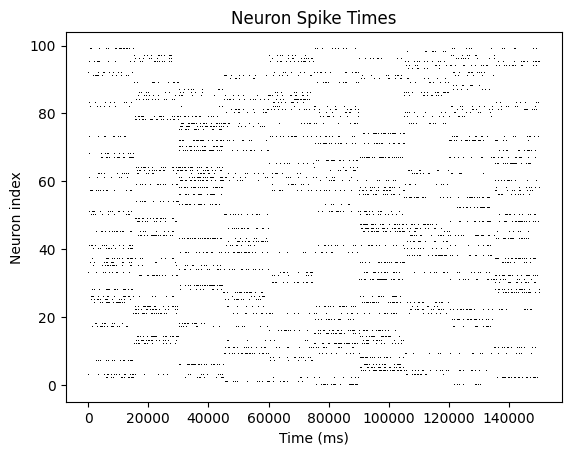

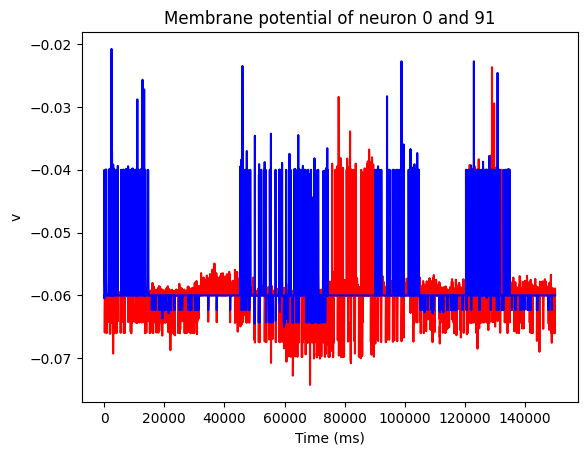

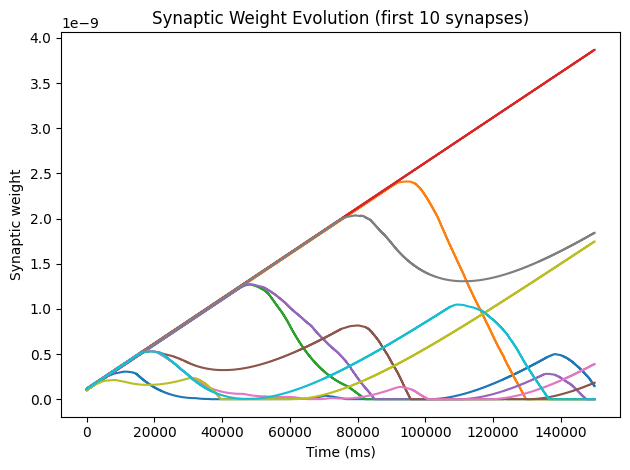

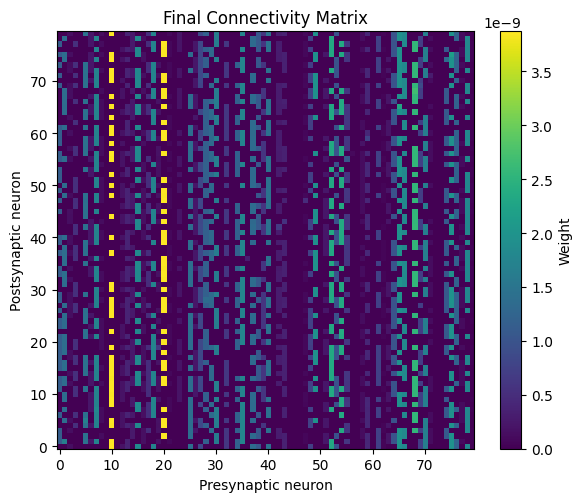

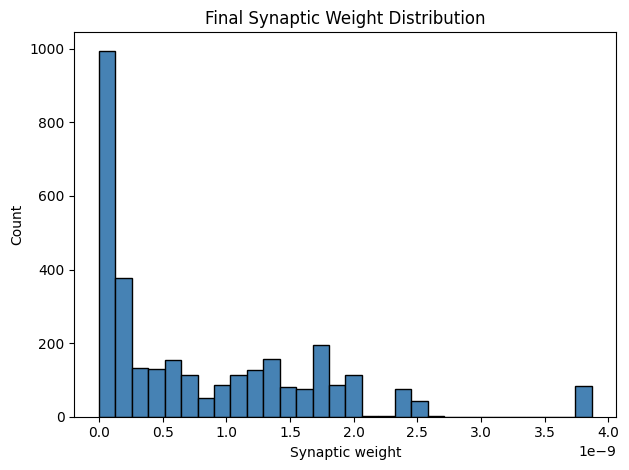

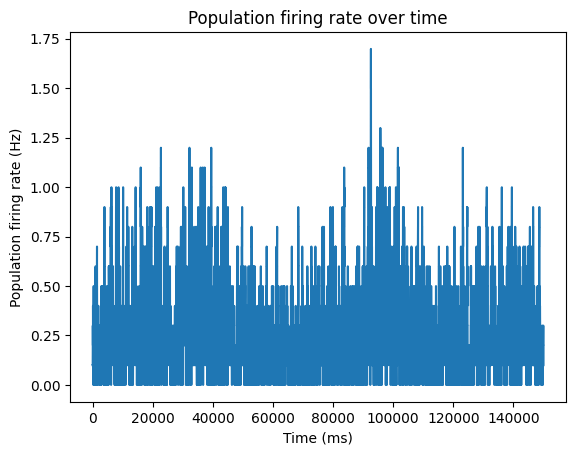

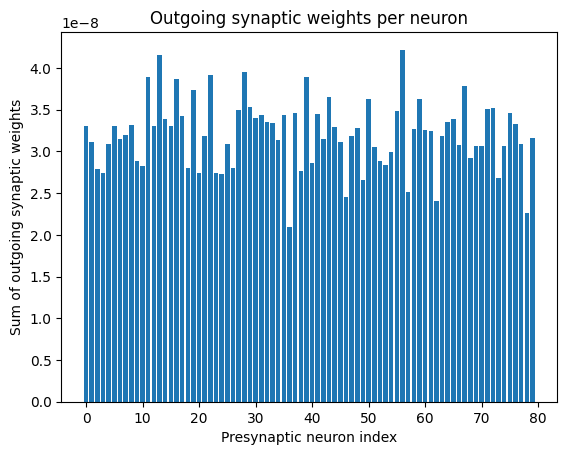

<Figure size 640x480 with 0 Axes>

In [27]:
from brian2 import *
import matplotlib.pyplot as plt

start_scope()

N_e = 80 
N_i = 20  
N = N_e + N_i
time_simu = 150*second
refractory_period = 5*ms

tau_homeo = 20*second
target_firing_rate = 5 
alpha = 0.0005*nS
w_max = 100*nS

stim_N = 30
stim_rate = 3*Hz
change_interval = 15*second
n_steps = int(time_simu/change_interval)


# alcohol‐withdrawal current window
t_on       = 50*second
t_off      = 100*second

#Neuron cst
E_l    = -60.0*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
V_th   = -40*mV
V_r    = E_l

alco_e= 0.5
alco_i= 1
eqs_neurons = '''
dv/dt = (g_l*(E_l-v) + g_e*(1-alco_e*aa)*(E_e-v) + g_i*(1+alco_i*aa)*(E_i-v) + I)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens  
dg_i/dt = -g_i/tau_i : siemens
aa = int(t >= t_on and t < t_off) : 1
I : ampere
'''


neurons = NeuronGroup(
    N, model=eqs_neurons,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l' #+ rand()*(V_th - E_l)
neurons.g_e = 'rand()*0.05*nS'  
neurons.g_i = 'rand()*1.0*nS'
neurons.I = 0.0*pA


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : volt', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = 20*mV #'0.5*mV + 0.4*rand()*mV'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1




eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : siemens
'''


A_plus = 0.01*nS  # potentiation amplitude
A_minus = 0.012*nS  # depression amplitude 

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        g_e_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0*nS, w_max)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0*nS, w_max)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect(p=0.5)
exc_syn.w = '0.1*nS + 0.02*nS*rand()'
exc_syn.synaptic_activity = 0
exc_syn.taupre = 20*ms
exc_syn.taupost = 20*ms

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0*nS, w_max)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : siemens', on_pre='g_i_post += w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0*nS  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : siemens', on_pre='g_i_post += w_inh_all')
inh_syn_all.connect(p=0.2)
inh_syn_all.w_inh_all = 5.0*nS
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,91])
weight_mon = StateMonitor(exc_syn, 'w', record=range(10))  #100
rate_mon = PopulationRateMonitor(neurons)

run(duration=time_simu, report = 'text')

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 91')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(10, len(weight_mon.w))):  # Plot only a few synapses for clarity
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 10 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

#Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:]/siemens, bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w/siemens
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()

WARNING    'i' is an internal variable of group 'synapses_8', but also exists in the run namespace with the value 79. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 6.94581968 * psiemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses_4', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]
WARNING    'w' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 33.00005282 * psiemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 43.00005282 * psiemens. The internal variable will be used. [br

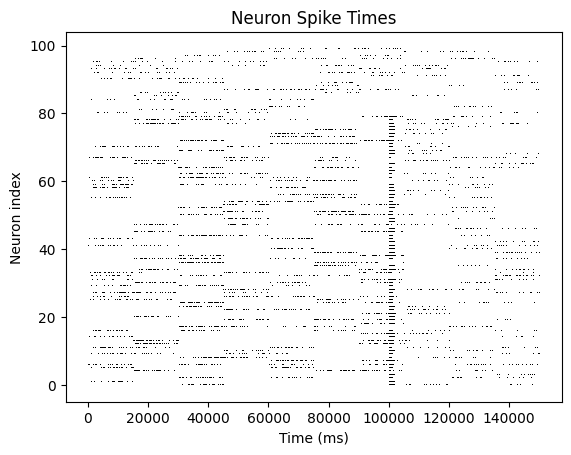

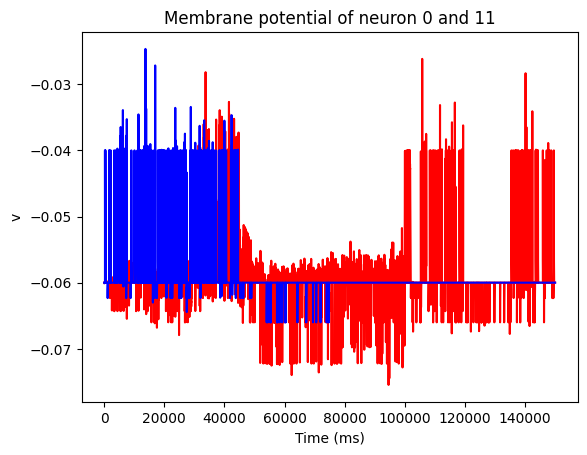

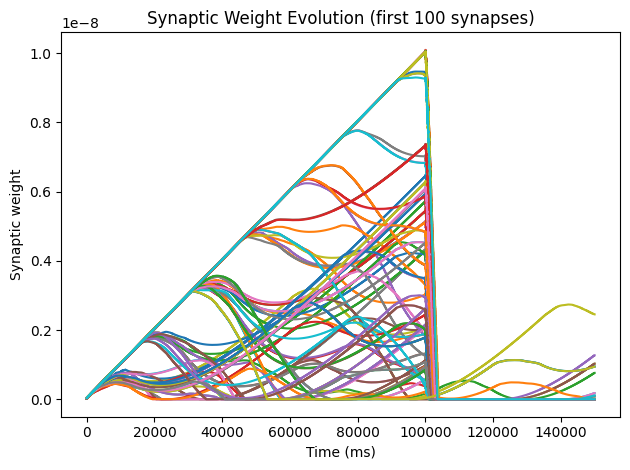

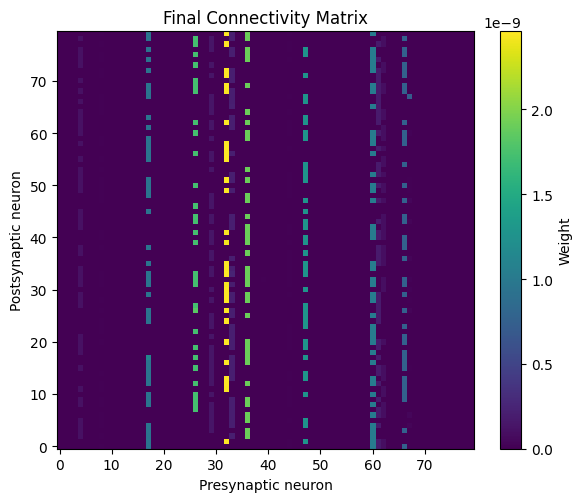

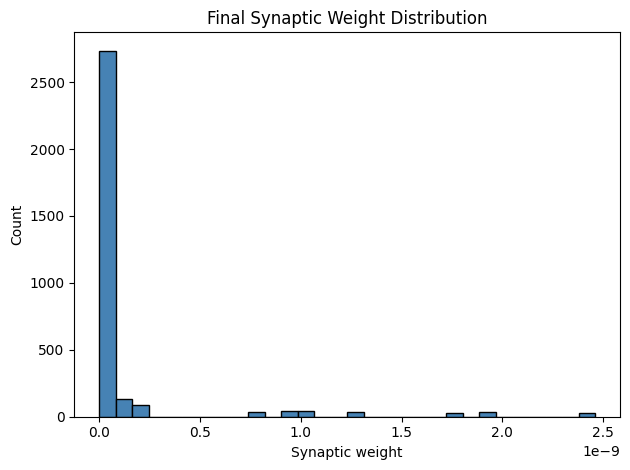

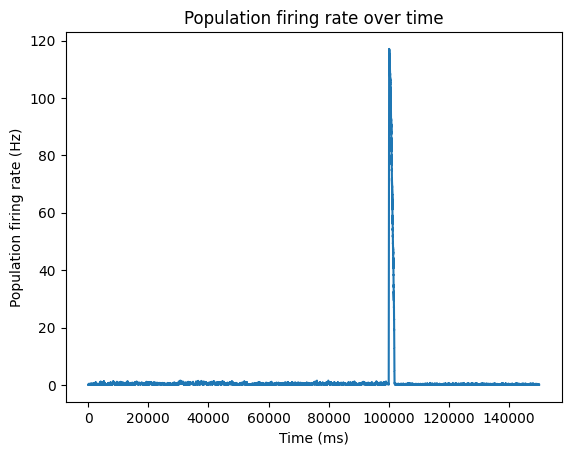

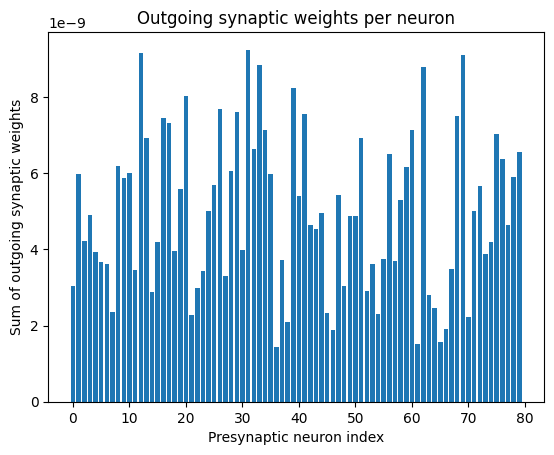

<Figure size 640x480 with 0 Axes>

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np
import imageio
import os

start_scope()

N_e = 80 
N_i = 20  
N = N_e + N_i
time_simu = 150*second
save_interval = 0.1*second   
refractory_period = 5*ms

tau_homeo = 20*second
target_firing_rate = 10 
alpha = 0.001*nS
w_max = 100*nS

stim_N = 30
stim_rate = 3*Hz
change_interval = 15*second
n_steps = int(time_simu/change_interval)


# alcohol‐withdrawal current window
t_on       = 50*second
t_off      = 100*second

#Neuron cst
E_l    = -60.0*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
V_th   = -40*mV
V_r    = E_l

alco_e= 0.5
alco_i= 2
eqs_neurons = '''
dv/dt = (g_l*(E_l-v) + g_e*(1-alco_e*aa)*(E_e-v) + g_i*(1+alco_i*aa)*(E_i-v) + I)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens  
dg_i/dt = -g_i/tau_i : siemens
aa = int(t >= t_on and t < t_off) : 1
I : ampere
'''


neurons = NeuronGroup(
    N, model=eqs_neurons,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l' #+ rand()*(V_th - E_l)
neurons.g_e = 'rand()*0.05*nS'  
neurons.g_i = 'rand()*1.0*nS'
neurons.I = 0.0*pA


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : volt', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = 20*mV #'0.5*mV + 0.4*rand()*mV'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1




eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : siemens
'''


A_plus = 0.01*nS  # potentiation amplitude
A_minus = 0.012*nS  # depression amplitude 

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        g_e_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0*nS, w_max)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0*nS, w_max)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect('i != j',p=0.5)
exc_syn.w = '0.02*nS + 0.02*nS*rand()'
exc_syn.synaptic_activity = 0
exc_syn.taupre = 20*ms
exc_syn.taupost = 20*ms

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0*nS, w_max)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : siemens', on_pre='g_i_post += w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0*nS  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : siemens', on_pre='g_i_post += w_inh_all')
inh_syn_all.connect(p=0.2)
inh_syn_all.w_inh_all = 5.0*nS
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,90])
weight_mon = StateMonitor(exc_syn, 'w', record=range(100))  #10
rate_mon = PopulationRateMonitor(neurons)

#run(duration=time_simu, report = 'text')

n_saves = int(time_simu / save_interval)
conn_matrices = []
image_files = []

for snap in range(n_saves):
    run(save_interval)
    conn_matrix = np.zeros((N_e, N_e))
    for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
        conn_matrix[i, j] = w
    conn_matrices.append(conn_matrix.copy())
    # Plot and save image
    plt.figure(figsize=(5, 4))
    plt.imshow(conn_matrix, cmap='viridis', origin='lower', vmin=0, vmax=1e-8)
    plt.colorbar(label='Weight')
    plt.title(f'Connectivity at t={((snap+1)*float(save_interval/second)):.0f}s')
    plt.xlabel('Presynaptic neuron')
    plt.ylabel('Postsynaptic neuron')
    plt.tight_layout()
    img_name = f'conn_matrix_{snap:03d}.png'
    plt.savefig(img_name)
    plt.close()
    image_files.append(img_name)

# Make gif
with imageio.get_writer('conductance_evolution_HP_HL_AWS_alpha_001.gif', mode='I', duration=5.0) as writer:
    for filename in image_files:
        image = imageio.imread(filename)
        writer.append_data(image)

for fname in image_files:
    os.remove(fname)

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 100 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

#Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:]/siemens, bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w/siemens
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()

WARNING    'i' is an internal variable of group 'synapses_4', but also exists in the run namespace with the value 79. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0. * siemens. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
INFO       No numerical integration method specified for group 'synapses', using method 'exact' (took 0.00s). [brian2.stateupdaters.base.method_choice]


Starting simulation at t=0. s for a duration of 200. s
9.9407 s (4%) simulated in 10s, estimated 3m 11s remaining.
18.9361 s (9%) simulated in 20s, estimated 3m 11s remaining.
26.0784 s (13%) simulated in 30s, estimated 3m 20s remaining.
29.6015 s (14%) simulated in 40s, estimated 3m 50s remaining.
32.9515 s (16%) simulated in 50s, estimated 4m 13s remaining.
36.4483 s (18%) simulated in 1m 0s, estimated 4m 29s remaining.
39.859 s (19%) simulated in 1m 10s, estimated 4m 41s remaining.
43.9075 s (21%) simulated in 1m 20s, estimated 4m 44s remaining.
47.9926 s (23%) simulated in 1m 30s, estimated 4m 45s remaining.
52.4402 s (26%) simulated in 1m 40s, estimated 4m 41s remaining.
56.2622 s (28%) simulated in 1m 50s, estimated 4m 41s remaining.
59.5969 s (29%) simulated in 2m 0s, estimated 4m 43s remaining.
64.0363 s (32%) simulated in 2m 10s, estimated 4m 36s remaining.
68.5516 s (34%) simulated in 2m 20s, estimated 4m 28s remaining.
72.6518 s (36%) simulated in 2m 30s, estimated 4m 23s re

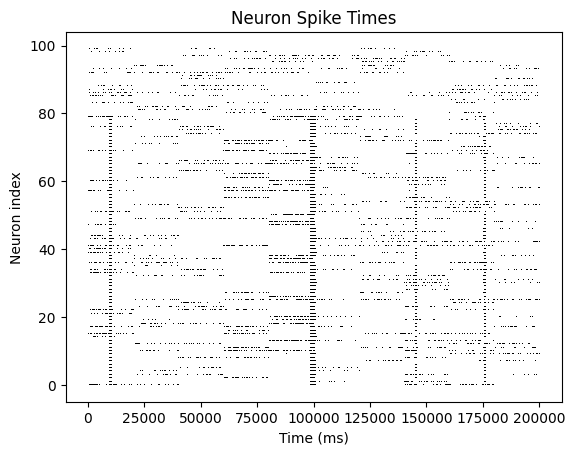

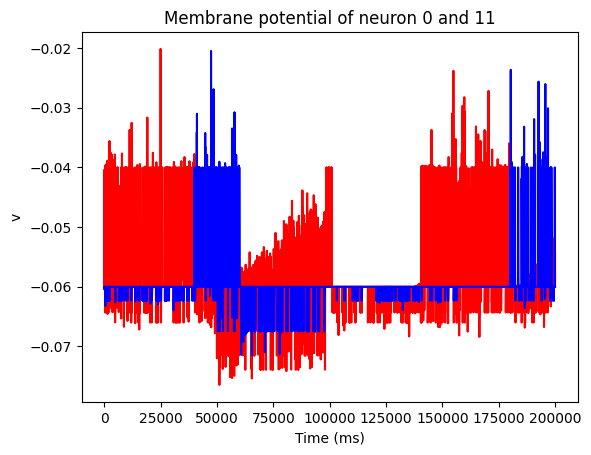

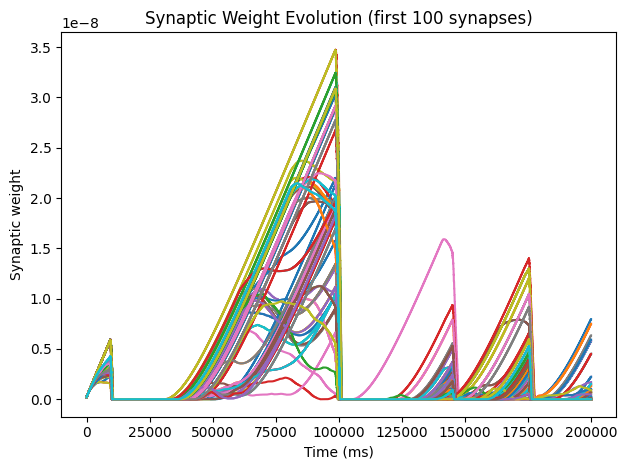

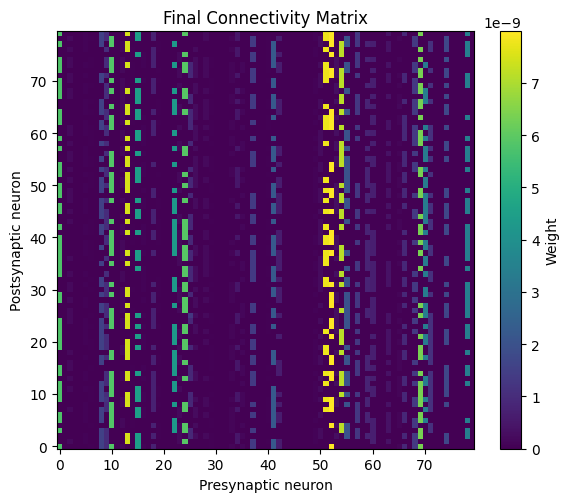

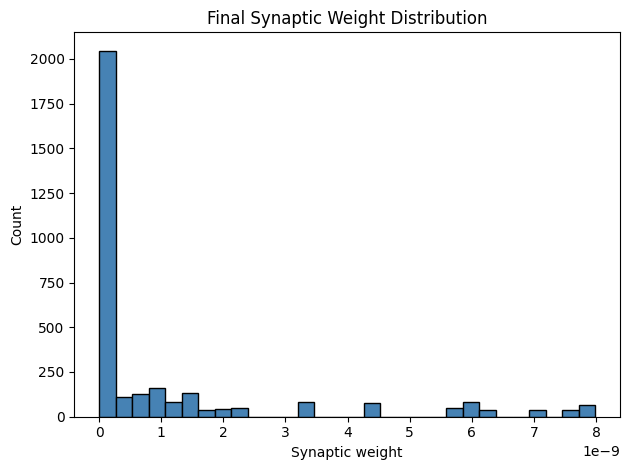

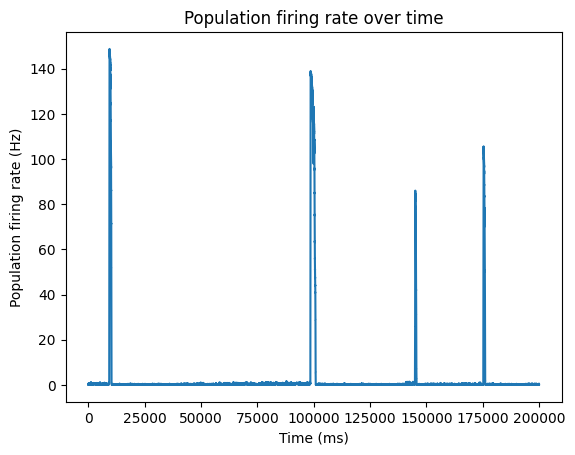

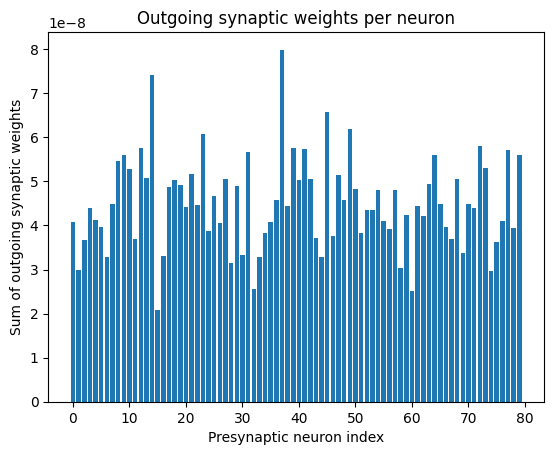

<Figure size 640x480 with 0 Axes>

In [ ]:
from brian2 import *
import matplotlib.pyplot as plt
import numpy as np
import imageio
import os

start_scope()

N_e = 80 
N_i = 20  
N = N_e + N_i
time_simu = 200*second
save_interval = 0.1*second   
refractory_period = 5*ms

tau_homeo = 10*second
target_firing_rate = 10 
alpha = 0.006*nS
w_max = 100*nS

stim_N = 30
stim_rate = 3*Hz
change_interval = 20*second
n_steps = int(time_simu/change_interval)


# alcohol‐withdrawal current window
t_on       = 50*second
t_off      = 100*second

#Neuron cst
E_l    = -60.0*mV
g_l    =  9.8*nS
E_e    =   0*mV
E_i    = -80*mV
C_m    = 200*pF
tau_e  =   5*ms
tau_i  =  10*ms
tau_r  =   5*ms
V_th   = -40*mV
V_r    = E_l

alco_e= 0.8
alco_i= 3
eqs_neurons = '''
dv/dt = (g_l*(E_l-v) + g_e*(1-alco_e*aa)*(E_e-v) + g_i*(1+alco_i*aa)*(E_i-v) + I)/C_m : volt (unless refractory)
dg_e/dt = -g_e/tau_e : siemens  
dg_i/dt = -g_i/tau_i : siemens
aa = int(t >= t_on and t < t_off) : 1
I : ampere
'''


neurons = NeuronGroup(
    N, model=eqs_neurons,
    threshold='v>V_th', reset='v=V_r',
    refractory='tau_r', method='euler'
)
neurons.v   = 'E_l' #+ rand()*(V_th - E_l)
neurons.g_e = 'rand()*0.05*nS'  
neurons.g_i = 'rand()*1.0*nS'
neurons.I = 0.0*pA


poisson_input = PoissonGroup(N, rates=0*Hz)
input_syn = Synapses(poisson_input, neurons,'w_in : volt', on_pre='v_post += w_in')
input_syn.connect(j='i')
input_syn.w_in = 20*mV #'0.5*mV + 0.4*rand()*mV'

stim_targets = [np.random.choice(N, stim_N, replace=False) for _ in range(n_steps)]
current_step = 0

@network_operation(dt=change_interval)
def update_poisson_rates():
    global current_step
    rates = np.zeros(N) * Hz      
    rates[stim_targets[current_step]] = stim_rate
    poisson_input.rates = rates   
    current_step += 1
    if current_step >= n_steps:
        current_step = n_steps - 1




eqs_syn = '''
dsynaptic_activity/dt = -synaptic_activity / tau_homeo : 1 (clock-driven)
dpre_trace/dt = -pre_trace / taupre : 1 (clock-driven)
dpost_trace/dt = -post_trace / taupost : 1 (clock-driven)
taupre : second (constant)
taupost : second (constant)
w : siemens
'''


A_plus = 0.01*nS  # potentiation amplitude
A_minus = 0.012*nS  # depression amplitude 

exc_syn = Synapses(neurons[:N_e], neurons[:N_e], model=eqs_syn,
    on_pre='''
        g_e_post += w
        pre_trace += 1
        w += A_plus * post_trace
        w = clip(w, 0*nS, w_max)
    ''',
    on_post='''
        post_trace += 1
        w -= A_minus * pre_trace
        w = clip(w, 0*nS, w_max)
        synaptic_activity += 1
    ''',
    delay=rand()*2*ms
)
#,namespace={'A_plus': A_plus, 'A_minus': A_minus, 'tau_pre': tau_pre, 'tau_post': tau_post, 'tau_homeo': tau_homeo}

exc_syn.connect(p=0.5)
exc_syn.w = 0.2*nS #'0.1*nS + 0.02*nS*rand()'
exc_syn.synaptic_activity = 0
exc_syn.taupre = 20*ms
exc_syn.taupost = 20*ms

exc_syn.run_regularly('''
    firing_rate_diff = target_firing_rate - synaptic_activity
    w += alpha * firing_rate_diff
    w = clip(w, 0*nS, w_max)
''', dt=100*ms)

# Inhibitory synapses
inh_syn = Synapses(neurons[N_e:], neurons[:N_e], 'w_inh : siemens', on_pre='g_i_post += w_inh')
inh_syn.connect(p=0.5)
inh_syn.w_inh = 10.0*nS  
inh_syn.delay = rand()*2*ms

# Optionally, connect inhibition to all neurons
inh_syn_all = Synapses(neurons[N_e:], neurons, 'w_inh_all : siemens', on_pre='g_i_post += w_inh_all')
inh_syn_all.connect(p=0.2)
inh_syn_all.w_inh_all = 5.0*nS
inh_syn_all.delay = rand()*2*ms


# Monitors
spikemon = SpikeMonitor(neurons)
statemon = StateMonitor(neurons, 'v', record=[0,90])
weight_mon = StateMonitor(exc_syn, 'w', record=range(100))  #10
rate_mon = PopulationRateMonitor(neurons)

run(duration=time_simu, report = 'text')

# n_saves = int(time_simu / save_interval)
# conn_matrices = []
# image_files = []

# for snap in range(n_saves):
#     run(save_interval)
#     conn_matrix = np.zeros((N_e, N_e))
#     for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
#         conn_matrix[i, j] = w
#     conn_matrices.append(conn_matrix.copy())
#     # Plot and save image
#     plt.figure(figsize=(5, 4))
#     plt.imshow(conn_matrix, cmap='viridis', origin='lower', vmin=0, vmax=1e-8)
#     plt.colorbar(label='Weight')
#     plt.title(f'Connectivity at t={((snap+1)*float(save_interval/second)):.0f}s')
#     plt.xlabel('Presynaptic neuron')
#     plt.ylabel('Postsynaptic neuron')
#     plt.tight_layout()
#     img_name = f'conn_matrix_{snap:03d}.png'
#     plt.savefig(img_name)
#     plt.close()
#     image_files.append(img_name)

# # Make gif
# with imageio.get_writer('conductance_evolution_HP_HL_AWS_alpha_001.gif', mode='I', duration=5.0) as writer:
#     for filename in image_files:
#         image = imageio.imread(filename)
#         writer.append_data(image)

# for fname in image_files:
#     os.remove(fname)

# Plot
plt.plot(spikemon.t/ms, spikemon.i, ',k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Neuron Spike Times')
plt.show()

plt.figure()
plt.plot(statemon.t/ms, statemon.v[0],color='red')
plt.plot(statemon.t/ms, statemon.v[1],color='blue')
plt.title('Membrane potential of neuron 0 and 11')
plt.xlabel('Time (ms)')
plt.ylabel('v')
plt.show()

# Weight dynamics
plt.figure()
for i in range(min(100, len(weight_mon.w))):  
    plt.plot(weight_mon.t/ms, weight_mon.w[i])
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic weight')
plt.title('Synaptic Weight Evolution (first 100 synapses)')

plt.tight_layout()
plt.show()

# Final connectivity matrix
plt.figure(figsize=(6, 5))
conn_matrix = np.zeros((N_e, N_e))
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    conn_matrix[i, j] = w
plt.imshow(conn_matrix, cmap='viridis', origin='lower')
plt.colorbar(label='Weight')
plt.title('Final Connectivity Matrix')
plt.xlabel('Presynaptic neuron')
plt.ylabel('Postsynaptic neuron')
plt.tight_layout()
plt.show()

#Final weight histogram
plt.figure()
plt.hist(exc_syn.w[:]/siemens, bins=30, color='steelblue', edgecolor='black')
plt.xlabel('Synaptic weight')
plt.ylabel('Count')
plt.title('Final Synaptic Weight Distribution')
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(rate_mon.t/ms, rate_mon.smooth_rate(window='flat', width=100*ms)/Hz)
plt.xlabel('Time (ms)')
plt.ylabel('Population firing rate (Hz)')
plt.title('Population firing rate over time')
plt.show()

outgoing_w = np.zeros(N_e)
for i, j, w in zip(exc_syn.i[:], exc_syn.j[:], exc_syn.w[:]):
    outgoing_w[i] += w/siemens
plt.figure()
plt.bar(np.arange(N_e), outgoing_w)
plt.xlabel('Presynaptic neuron index')
plt.ylabel('Sum of outgoing synaptic weights')
plt.title('Outgoing synaptic weights per neuron')
plt.show()

plt.tight_layout()
plt.show()